In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import glob

from ISRpy import beampack
jro0 = beampack.jrobeam

from IPython import display

import numpy as np

In [3]:
from OXmodeCython import OXmode_cython

In [14]:
def fps_gauss(a,z):
    result = a[0]*np.exp(-(z-a[1])**2/1000/a[2])
    result += a[3]*np.exp(-(z-a[4])**2/1000/a[5])
    return (result*80.6)**0.5

# def fps_para(a,z):
#     def softplus(x):
#         return np.log(1+np.exp(x))
#     para1 = a[0]-((z-a[1])/a[2]/3)**2
#     para2 = a[3]-((z-a[4])/a[5]/3)**2
#     return (softplus(para1) + softplus(para2))**0.5

In [242]:
# from matplotlib.widgets import Slider
from matplotlib import pyplot as plt
from matplotlib import rcParams
import scipy.interpolate as inter
import numpy as np
import datetime
import scipy.constants as const
import time


def graph_generate(params):
    try:
        ppparam, fes, dz = params
        #figure.subplot.right
        rcParams['figure.subplot.right'] = 0.78
        #set up a plot
        fig,axes = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        ax1 = axes
        fps=fps_para(ppparam, Z)
        ax1.plot(fps,Z)
        # start = time.time()
        fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz) # x1 y1 x2 y2 

        def scatter_noise_around_points(x_data : np.ndarray, y_data : np.ndarray, sigma_x = 0.05, sigma_y = 5, max_points=10):
            noisy_x = x_data.tolist()
            noisy_y = y_data.tolist()

            for x, y in zip(x_data, y_data):
                num_points = np.random.randint(1, max_points+1)  # Random number of points
                for _ in range(num_points):
                    dx = np.random.normal(0, sigma_x) * 0
                    dy = np.random.normal(0, sigma_y)
                    noisy_x.append(x + dx)
                    noisy_y.append(y + dy)

            return np.array(noisy_x), np.array(noisy_y)

        # Generate noisy data
        fvsO_noisy_x, vhsO_noisy_y = scatter_noise_around_points(fvsO, vhsO)
        fvsX_noisy_x, vhsX_noisy_y = scatter_noise_around_points(fvsX, vhsX)

        # Generate random illumination values for each point
        illumination_O = np.random.rand(len(fvsO_noisy_x))
        illumination_X = np.random.rand(len(fvsX_noisy_x))

        sizes_O = np.random.normal(0.1, 0.5, len(fvsO_noisy_x))  # Random sizes between 1 and 50 for O-trace
        sizes_X = np.random.normal(0.1, 0.5, len(fvsX_noisy_x))  # Random sizes between 1 and 50 for X-trace

        # Scatter the noisy data with random illumination
        scatter_O = ax1.scatter(fvsO_noisy_x, vhsO_noisy_y, c=illumination_O, cmap='gray', s=sizes_O, label='O-trace hv')
        scatter_X = ax1.scatter(fvsX_noisy_x, vhsX_noisy_y, c=illumination_X, cmap='gray', s=sizes_X, label='X-trace hv')

        ax1.set_axis_off()

        def add_background_noise(ax, num_points=500, color='0.8', s=1):
            # Get the extent of the current graph
            x_min, x_max = ax.get_xlim()
            y_min, y_max = ax.get_ylim()

            # Generate random x and y coordinates within this extent
            random_x = np.random.uniform(x_min, x_max, num_points)
            random_y = np.random.uniform(y_min, y_max, num_points)
            sizes_X = np.random.normal(0.1, 0.5, num_points) 
            illumination_X = np.random.rand(num_points)
            # Scatter these points on the graph
            ax.scatter(random_x, random_y, c=illumination_X, s=sizes_X,cmap='gray', label='Background Noise')

        # Assuming you've already created an Axes object named ax1 and added your data to it
#         add_background_noise(ax1)
        def add_noisy_lines(ax, num_lines=2, num_points_per_line=1000, noise_level=0.1, max_size=1):
            x_min, x_max = ax.get_xlim()
            y_min, y_max = ax.get_ylim()

            for _ in range(num_lines):
                # Randomly select two endpoints for the line segment
                x_start, x_end = np.random.uniform(x_min, x_max, 2)
                y_start, y_end = np.random.uniform(y_min, y_max, 2)

                # Generate linear points between the endpoints
                x_values = np.linspace(x_start, x_end, num_points_per_line)
                y_values = np.linspace(y_start, y_end, num_points_per_line)

                # Perturb the points to make the line non-linear
                x_values += np.random.normal(0, noise_level, num_points_per_line)
                y_values += np.random.normal(0, noise_level, num_points_per_line)

                # Assign random illumination and size to each point
                colors = np.random.rand(num_points_per_line)
                sizes = np.random.uniform(0, max_size, num_points_per_line)

                ax.scatter(x_values, y_values, c=colors, s=sizes, cmap='gray')


#         x_min, x_max = min(min(fvsO), min(fvsX)), max(max(fvsO), max(fvsX))
#         y_min, y_max = min(min(vhsO), min(vhsX)), max(max(vhsO), max(vhsX))
        x_min, x_max = (0,12)
        y_min, y_max = (0,800)
        ax1.set_xlim(x_min, x_max)
        ax1.set_ylim(y_min, y_max)
#         print(xvals)
        file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        # fig.savefig(f"training_data_transparent_doublegauss/train/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
        
        fig,axe = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        axe.set_axis_off()
        axe.set_xlim(x_min, x_max)
        axe.set_ylim(y_min, y_max)
        scatter_O = axe.scatter(fvsO_noisy_x, vhsO_noisy_y, c='b', s=sizes_O, label='O-trace hv')
#         file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        # fig.savefig(f"training_data_transparent_doublegauss/O/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
        
        fig,axe = plt.subplots(1,1,figsize=(10.0,8.0),sharex=True)
        axe.set_axis_off()
        axe.set_xlim(x_min, x_max)
        axe.set_ylim(y_min, y_max)
        scatter_X = axe.scatter(fvsX_noisy_x, vhsX_noisy_y, c='r', s=sizes_X, label='X-trace hv')
#         file_name = "_".join([f"{x:.5f}" for x in ppparam]) + "_.png"
        # fig.savefig(f"training_data_transparent_doublegauss/X/{file_name}", dpi=100, bbox_inches='tight', pad_inches=0, facecolor=fig.get_facecolor())
        plt.show()
    except:
        print('error')
        pass
#         plt.plot(fps,Z)



In [38]:
import random
dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()
dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmax = 800
Z = np.arange(0.01,zmax,dz)
fes = []
for iZ in Z:
    r,geoc_lat,lon,aspect,B = jro0.aspect_angle(igrf_year,jro0.xyz0 + jro0.zenith0 * iZ)
    fes += [const.e * np.linalg.norm(B) * 1e-9 / const.m_e /1e6 /2/np.pi] #MHz
fes = np.array(fes)

param = np.array([random.uniform(0.75, 1.20) * 10,
         random.uniform(350, 500),
         random.uniform(0.75,1.25) * 25,  
         random.uniform(0.8,1.2) * 2,  
         random.uniform(100,150),
         random.uniform(0.8,1.2) * 20])
# print(param, len(param))
graph_generate((param,fes,dz))

NameError: name 'const' is not defined

In [ ]:
from joblib import Parallel, delayed
import random 
import os
import multiprocessing as mp
from multiprocessing import Pool

# Generate parameters for the images
parameters = []
for i in range(30000):  # Adjusted to generate 1000 sets of paramete
    igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()
    param = [random.uniform(0.75, 1.2) * 10,
         random.uniform(300, 500),
         random.uniform(0.75,1.25) * 22,  
         random.uniform(0.75,1.25) * 3.2,  
         random.uniform(90,170),
         random.uniform(0.75,1.25) * 10] 
    parameters += [(param,fes,dz)]

# Use all available CPU cores to generate the graphs in parallel
Parallel(n_jobs=mp.cpu_count()-8)(delayed(graph_generate)(p) for p in parameters)
# processes_pool = Pool(20)
# processes_pool.map(graph_generate, parameters)
# processes_pool.close()
# elapsed_time = time.time() - start_time
# print(f'Generated 1000 images. Time elapsed: {elapsed_time:.2f} seconds')



In [51]:
def fps_parabolic(a,z,beta=5):
    def softplus(x):
        return 1/beta*np.log(1+np.exp(x*beta))
    para1 = a[0]-((z-a[1])/a[2]/3)**2
    para2 = a[3]-((z-a[4])/a[5]/3)**2
    fps1 = (80.6*(softplus(para1) + softplus(para2)))**0.5
    fps2 = (80.6*np.max(np.vstack([para1,para2]), axis=0))**0.5
    # fps2 = (para1>0) *para1 + (para2>0)*para2
    return fps1,fps2


/var/folders/j2/rcdblwzs32zb_73_tzylc9l40000gn/T/ipykernel_58635/1239522286.py:7: RuntimeWarning: invalid value encountered in sqrt
  fps2 = (80.6*np.max(np.vstack([para1,para2]), axis=0))**0.5


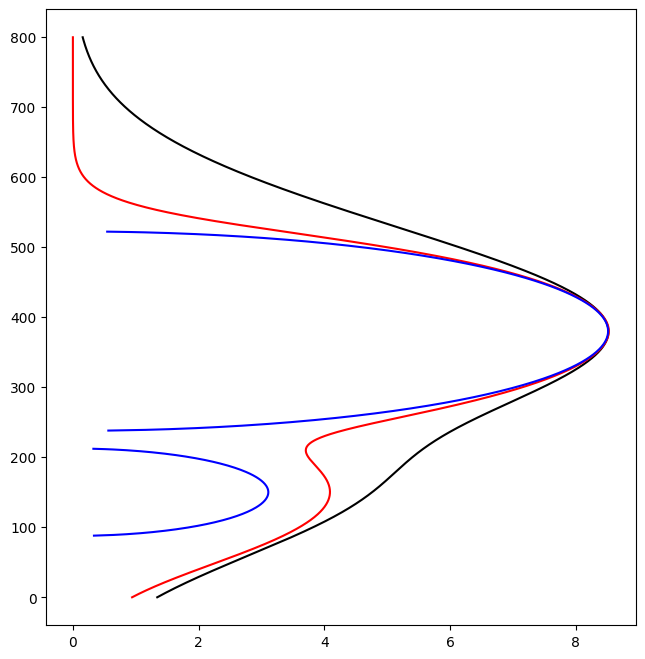

In [69]:

dt0 = datetime.datetime(2015,4,15)
igrf_year = dt0.year + (dt0-datetime.datetime(dt0.year,1,1)).total_seconds() / (
        datetime.datetime(dt0.year+1,1,1)-datetime.datetime(dt0.year,1,1)).total_seconds()

dz=0.5 # resolution in km --- 0.1 is for good resolution, 0.5 for speed
zmin = 0
zmax = 800

rcParams['figure.subplot.right'] = 0.78
#set up a plot
fig,axes = plt.subplots(1,1,figsize=(9.0,8.0),sharex=True)
ax1 = axes

# height grid
Z = np.arange(0.01,zmax,dz)

fps=fps_gauss(np.array([0.9,380,22,0.2,150,10]),Z)
m, = ax1.plot (fps, Z, 'k-', label='spline fp')

fps1, fps2=fps_parabolic(np.array([0.9,380,50,0.12,150,60]),Z)
m, = ax1.plot (fps1, Z, 'r-', label='spline fp')
m, = ax1.plot (fps2, Z, 'b-', label='spline fp')

# start = time.time()
# fvsO,vhsO,fvsX,vhsX=OXmode_cython(fps,fes,dz)
# mO, = ax1.plot (fvsO, vhsO, 'g-', label='O-trace hv')
# mX, = ax1.plot (fvsX, vhsX, 'y-', label='X-trace hv')
# print('new oxmode:',time.time() - start)

# ax1.set_yscale('linear')
# ax1.set_xlim(0,12)
# ax1.set_ylim(0,zmax)
# ax1.set_xlabel('fp, fv (MHz)')
# ax1.set_ylabel('z, hv (km)')
# ax1.grid(True)
# ax1.yaxis.grid(True,which='minor',linestyle='--')
# ax1.legend(loc=2,prop={'size':11})


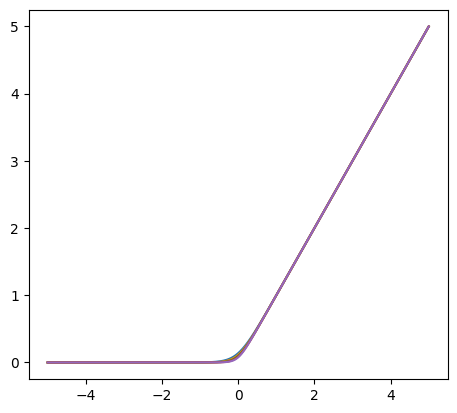

In [55]:
x = np.arange(-5,5,0.001)
for beta in range(5,10):
    plt.plot(x,1/beta*np.log(1+np.exp(x*beta)))
# plt.plot(x,(x>0)*x)
# plt.plot(x,np.log(1+np.exp(x))-(x>0)*x)